# Statistical Modelling and Inferencing — Graded Assignment
**Student:** Atharva Sandeep Raut  
**BITS ID:** [Enter your BITS ID before submission]  
**Course:** MDS DF401 | **Cohort:** 4  
**Submission date:** 16 November 2026

The filename uses `YourBITSID` because the actual ID was not supplied. Replace that filename
prefix and the identification field above before submitting this single notebook.

Environment: Python 3.11+ with pandas, NumPy, seaborn, matplotlib, SciPy, statsmodels,
scikit-learn and an IPython/Jupyter kernel. All data are embedded below; no network or sidecar
files are required when running the notebook.

## Summary
This investigation uses the genuine Auto MPG dataset to examine historical automobile characteristics and predict city-cycle fuel efficiency. Six missing horsepower values were excluded from 398 observations, giving a common 392-vehicle analytical sample. I retained valid statistical extremes, treated origin as categorical with USA as the reference and excluded car names from the predictors. Three OLS specifications were compared: weight alone, a full linear model and a reduced model with quadratic weight, model year and origin.

Five-fold validation within 313 training observations selected the reduced quadratic model (CV RMSE 3.033 MPG, adjusted training R-squared 0.857). On the untouched 79-vehicle holdout it achieved RMSE 3.048 MPG, MAE 2.261 MPG and R-squared 0.818, compared with RMSE 3.256 for the full linear model and 4.206 for the baseline. Reducing overlapping engine descriptors lowered the largest predictor VIF from 22.55 in the full model to 2.12 in the selected specification.

The selected model associates greater weight locally with lower MPG and later model years with higher MPG, conditional on origin, but these are observational relationships. Residual tests still detect unequal variance, non-normality and specification error. I therefore report HC3 coefficient inference and distinguish it from classical mean-response confidence and individual prediction intervals, whose nominal coverage is not assured. The model is a useful historical comparison, not a guarantee of modern-vehicle efficiency or a causal design recommendation.

## Part 1 — Data exploration and preparation (6 marks)
### Source and observational unit
I use the authentic 398-row Auto MPG dataset distributed in seaborn's official data repository,
corresponding to the UCI city-cycle fuel-efficiency dataset. The CSV is preserved byte-for-byte
inside this notebook as a compressed payload solely to allow a one-file, offline submission.
Decoding restores the original CSV; no synthetic records are introduced. `raw` remains unchanged
while I prepare a separate modelling copy. A row describes a historical vehicle observation,
not an experimental change to that vehicle.

Source: https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv  
Original documentation: https://archive.ics.uci.edu/dataset/9/auto+mpg
The seaborn columns `model_year` and `name` correspond to model year and car name; origin codes
are represented by named categories. MPG is miles per US gallon; weight is pounds and displacement
is cubic inches. The historical model years are 1970–1982.

In [1]:
# Libraries for data recovery, analysis, statistical inference and validation.
import io, base64, gzip, hashlib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.anova import anova_lm
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

%matplotlib inline
# Display settings affect presentation only, not stored numerical precision.
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")
RANDOM_SEED = 42
# Preserve the authentic source inside this one-file submission for offline use.
# This encoded string is source data, not a model feature or generated observations.
ORIGINAL_PAYLOAD = (
    "H4sIAAAAAAAC/5Vcy5bjOI7d+yu0m6ozzmy+Re7mT+YobGWEq2TLI9mRGfX1AwJ8S87pWXRX9WnB"
    "JEHgArgA43p/P56+psvtPC7r8XxZ79NwGq/j7XH8mJd1vM8/x+X4c7y8fzyOw+k0TuMyPC7z7Xid"
    "z+P031/jsBzn5fJ+uR1vw3U8cPudHe1Rsh7+ySWD/5aaqSMX8G89Oz7X4Xj6GD+XeRofnf+3cZrG"
    "7jpMl7fngWuS1l6OG/+/pHHyyPl3HaXfnpfT393699c0LH93UrC0Jv6To6xU0niptOZ9+rrOz8dH"
    "tw4PWPHygK2asFVVislqq8P11C3j2zh16/o48D5I+C+4Ignljpzl7f2Yl3P3AJXc5ngcJZz/3vnt"
    "Kam4/55V378P0/DrMnaawWkUCWn/TyEYCml1dHsKvFzvIJpkcEsCl1WSi6PN+0oK+PFcvrrL5ZIX"
    "0rgQCimhq93d59vjMpy60/CAG7oN6YYc3hD+t7SalSt5nQ3Xt2Fdh/O8dOf7lKSs9FI9WYWR1VLn"
    "+fw+gkUMYA+393Hp1jFuUSqyB5QzzB3tzsX+x+l5Hjr4NKmdsXyxveGgQb3V4BVOCMsOyzTvaUQy"
    "a6ptkvmN6wPsqPs5vM+37o/1558H4WXBzrk/osMfkL044l5A9K/hPtyOj/lrfgzdaV7m2wBGDwYM"
    "FyG8OZlgICRqvR3qnds7P9fHuJDJexFvFc6bpeh7VYn4awAfvo2Pg+D4tUCFWFxA2/6IDlCa4XX4"
    "HBc43kH0eBj8YWvRpqS3ePp1Ost5eKzPW3efNGcHYbKA8v/OrdSwIAmMz2W+j8fPefp7BZWNtw7U"
    "xDsAkOevEe75PNwOZH+gP9wjnsh4/fXVT9zH5/s4P8BRVNI4Qg1aolDFLoPE8DxfOs5YN61pDfT4"
    "eEe6XWMdhrfOuTEeiqP66GKFkIhl5fdv158dqFZENYdLwQ0ZZZMJxEt5X8Yr+NKBTuoNOjut4fqI"
    "Vlheyw+hWfoaT0s3qcCqq1/3Vv3VnTwk8gISBaevLahTZgMhhzvDbx1ciYTOH1T1Er4uvPoDtAif"
    "nn9rG3zXNiypEZ2Y1AJ6CbbKG3f8HN+HTkjYUzKI7FBC2KAdvudQUQT9CHSk/F3Q10mX98vtAY7u"
    "yCEkAjmjq/I3K/Pn1VUZ+h4X4ExTqHDVGbYRpjuBs85XChsgTVENV5NSuBca2MREV0ijwiUEoEq4"
    "iDkUQuzmeFJYW8n4410B1QGiE8wWYVcJgFmKhPz3MYdQtqfw4e+VFzppwkf3tszP94/hmpdE39Jo"
    "clyrYKD8t6GxDPSKOVNd206cE2XwsSjltK42Sr4AsWA4zYTn+Jv5eCjVe4sSjUWd5uftAUut//O8"
    "LOOusNeNBvuvhKNu1uHHsFyCXLg4jQdEtxXOiEorGde79T4vj+ENjhtikCg8rReIiMxWTtB4Gq3q"
    "tvYpbIxd9W5/wBnfLss5bzWbJfceoZr7u4IPDLf3g5ABTPE2DLkzS+7sv7+Oy8lf2mm4g0IAbDJ2"
    "oAMSdnAhk1RAYPjP1EEywg6YcKpjT8kSIqUPi4421QQRwLsogAfocVfM6HSKIPDjMjwA/dTbQXL6"
    "fUR6BIO+l0nBG0yapgFR8yAJmfBODGaDhssj6rAFTfy+BFmMDxBPVVpnG08xG4eoylMk5lED3Ns6"
    "ReLGQ04+1vv0YJu6iD6ihdhNXT6G5fyY7wlxfQS14XrMEQEPJIu0bp4eWUjmw4UsFzxfSFpue7jH"
    "133s5IFS4SqOBOvWcbHauikgtzZnfN6TJHJQ6JbnDX0pem8Nh32sYcS/D4eQGVdCL7PpEtA4JE5c"
    "5h2+TNxr7PTxROalttjZb6sdTLB4XqrJ3LHk4UUJIxi6o5Ey1Fai8lvIZwED10Z/mEwrzUR1Kkqj"
    "p3Ed3pYcKEWleFSH0qYSnKfzep3fLhAgweTBIq3tlvlrmMYGdR2JCxHytXhvy9cKRWx3G3969CRZ"
    "gkBJDkPptPRJjSw94Dr8AwXG8kt4yL+P6fJKjVpXL1dE2SoylPUxhLCY1ohXucBpvsGiy9r8SK5D"
    "4YJUSOhLA1iGW0wMSHIvgvZ9tfzLRKaIUTkrxijjpAyYWfrv59xxpcc6NqEYIa3mPEDgntcrzoNk"
    "9OJcGbjeJb/fVgZBLAChiZAruHXtest4G56TB/dmlxkxpNNbxRJikIjNaOZQG5hqBQisoB2y4SAj"
    "iyORvWlmkgoz4j431WK9KDIfhLuUUu/hLkls03bGEhTuRy7DWG1wugA3FEfEkYVHn4A68lggdU7X"
    "9iFHbtPQahWFWbbzuixWKQr3kB6r0hcknpIpEXQpd31hD3dl791AZKGoQFC+98QKoSpGx+n6SA0c"
    "Fjmv3PASlDGLvfNhFnSCHUyAx5dT1g6hPpFJnkMptIMHnR7nXT+HWrfSSh1YUD1Uisd9lmxSL3XA"
    "fLnB0e5rXv6Gf80HFVtmyWle/UDgUabx9Fig4hM6qVgWZTHZGlSutXATqPLCdluncS9rdo79CQY0"
    "3B6puKvSX5//2L1ruc2fQ9rqts4CGI5wIVsaZidlZs3mGhpGboghx1T18y0xtCVinPaXSBJblF0h"
    "koECx/HhAyjfGqhzMTrIF4mPKIUMLuyYqXypLJTaC8ZVjFaVIecclSLP+nx7Lm9NgkClHOywWqtI"
    "ED4vq4ezBbwwc2bVbfXWBdSUm6I/5JsFYgoKO/h1jZhQwd1yvlnVXzxEKrmboYZ4g4mVU8RIuWQS"
    "VfQwPFT2MU8J+XYsmmXKU35hniIpq0nRjPguzgKtI1tSJNJXmpwHo5LqRXX7dYn2aZK92YLb0aF0"
    "kG39RAVrkz4VaA/pvHiF9pmm7dZI3ZPNCcqivMsWio65tsc1OOFy+XUQpA5DqI0WZPp0O/Veba6K"
    "0Ns0QaFtj4al5xVgZEj1CeoL6y+o47P6Gj4S6Mh0PUUmZc1miZhJqXG3YJDSO0ABjoHXG5YUteJR"
    "wkJEdxnWbi0QnwAEeBRvCogggnbG+sbQgvFHGjtyjoVzSkOEENtxzvmKDsBaiAMLFcEB1D7ElWw2"
    "7IsYXBY/ryF0j+lzjAcMVRuI1jtUnTTVAnUsSJQALtRHxCWYULUHv4lMlQenpDJW8+rEhVNK0RIO"
    "FrZDeK5+QzhE9pSgiCh/JV6cA6FoLwz2lr8QaVjKnKWYDYMFSYoIwVRtc76diI3UyJ4B5IJkHd8A"
    "cd9zD6+ohLjvsKnGIKrsr65PKQC5yF2pnWwW+hTP9XUFpXR0DfUydayly/0aaStz/H3lViTT0Kzr"
    "A1io/WozIB6VCdS/4C7ptkSkH/OvaJmlJRuZFtjmDudh/WhSjt4SILOkzC1ORofxYhr1YFTe1B6v"
    "H5wAT2A49T/kvov1ueHgsulzoavbzcVRxMbyY2bbQ+egYDZBQSiTzK2Nd49Txt5c6qmUdMTNf8w3"
    "CNmnyyd4UFyCUgJJJShPOyIByIeG5bnFHk+aJmMqd/OLf3cJDNHZCGyxE0OH2c2O21Q3oAN1QLSr"
    "ZBtgrLAUsyHomYiAXbouleCWl9PHngjGXAzReg/ezZalNz6E8izxknUrMw+lYjhsz+Kb/8NlSVBT"
    "OT4xN3qjPco6fGHVsHWKGLQEGLqp20KrSOZIDa32vlJaBU0tbFO55HN2m3+eDgNs2f7ARQPXvYzh"
    "S/8ersmCek9yuh0LwtPHYF0eiMlo/7qe6PgYfv5NGYGFBEVkCeHLJNkeKOSF/0D5+J+iIcUQ+SQ3"
    "sYmlNx0J7Ly7ArrI+XuebHovuibqBrGbMNX48/TNKiGnZjvpB69drqo5yl8nMNVOVJcZzXlYH8uc"
    "4EVi0omEVZ+oVv3bLikuwYkUjwFX/wbmYz6cRw600ungGxSOIwq4BH3vrKrcpVSUKzZF/K3sk0du"
    "N7UMb2+XR53e0TSK4Ly6Da/eOww1LUm5PBmvME4lU9wm6BVNRyWg857bVwLVTELJcjqbCAHVKhcy"
    "eqHUeUqJWsjNaVd9NvdNbi5lbvBomqdxcYZBb+NJd/o8nVIfDas64jVV6sGbOm5JnnvviHk8NevM"
    "d1d8nttuVbZJJKimyhG/R5fFitH7XFExYuACMMH99/HTMjr3Yd88ZzDU/JbFRjKL+5gOqAmPA7og"
    "x7kOdaX5/+SxbWfGsepX6jQvk1A6bAAzNUEYTk3cpI2m+64LYk+kDYvvNn6/yWHDzFDMm8nyaWhI"
    "RaEN0xWFylghdaTuzV4QR69Po0Mc4ZtjHWGqvWXOylMxtUcyqyuBcjKJ3B65CTy5YH5uSHwXL67q"
    "AYN7wm83WJBJ5DcI8a3Qz3k+f71GF1FY0efPiCovXQxVu5Oyse1lGM13jHpY7550G+t8CoFeakjZ"
    "QnekvvMBFnr/uAwHDAPp/kJxRXxj0lcMD5+YHwzd+hd5RAzyocb2Q5V9tq8Ekt35X5NXl05hEa3S"
    "CrTHSl0bMI5pus5a9h7T05HqSvibKBL1IvxqPE2h5zb8GtxaSbFpg85d22MRflXos3EWEkrvZXQx"
    "DR7rlESU/IpT6PZi61YzjKCOwC2N1wto7tNmRiczvBCO/a2WuFkGjBDAAtPCKGJIlpB5n2kxeKEc"
    "mayAMJbwuTyWz67H87h+extv/3RA4Kwk2RCo0uJgSnae4XwBVcNkyvgJ/zLu9WUU07G1bcrRMx/3"
    "qzyMJoBtz0KYLa7oBxx3V+G9jkNwpeucuZ+j4IXro7KYt39Mj/rKM2FYGUlnH/1kZOZ4bpfRGtaL"
    "5RwUI9plff7zDMOJB1nUxJQkoytYb259G3909/7AiK4TwUMpGRbEmjZZmdCwLPPP7n31kKMb3yHH"
    "tvlgwXd+fIM24sfwOH28Db4EquMdFQB0pWm933SV+pBtZ0hRzMQCoG9Ju9Pz4QV92wCsfkyxjq6P"
    "TIOTv/RRvJqtKqNkaybQVdMhZ+hrthlkhrLN029xUJP9q50jh975AYdgUi0SalihQ1rTb6fL64I5"
    "ArtkAdj7XTjIBXPeoyOAF7rSawnwTSVLnok5F/ee2b/gtLvpr3QHuqiBucF23Y42SiJ9gp8ZnvEH"
    "qrkJmQC/r/t93qvmt7TfWNYi8EkZU93igI+Pp39dgENjVb1lycpZEnkVWAoaGx0Ll6R0vFeR7qg1"
    "BH7iFwythoqh0qlJYel4uyTqdPnxQPeK3kz1HuariE86Y0dTVWI1KlkBVJi3Mh3rkv5VYhNAoKDr"
    "WI9LudqXsKt//dc1AhuNiRFjZ3Vyg5Iq6qDUiHvKRB1mtIoM7HXhF8bTsZ1IhZzl+aIrbLI+qvOA"
    "f2W3gbGQz/bl2DS83rjQ95JwOXzeizh80zfDN9/UQUnYcEjmlI2Hxl+BFtD/YUTd+TKu4+Rxnaf7"
    "oYF1Ii2V/5Ecoy5+0t9nNtZHAZsoS0esB35d7vB9OqXQ4f/vEtLhNlkIHXbbGOjef6Vd8Tz2xyKs"
    "2Ve1HWzDNRAOLYvYhLMvIXyY4O1CxlS/24zkgQnSIfOxZSC+3KcZihePp6KAcEdJbLxou8fwhTzW"
    "gWADxFqiQtNa0ZPvH/N4I6CL+I04FfJYHf3Y7o+H4B7rpw/ORPctLxooPg+N3R/D8zH/6d2eZ7e3"
    "ySh1ayBJDsjtP9MWy4ChKGDkk9UBgzTfchi1iE/PMYx5DGVgQI3yMIUrjlR3L6DmOF1gyA0kba0L"
    "iRaJWWN9Xf+M948vpPtMPk4oOAQacV8bBRY2/nue6URKTBXHvfGds2CxgZfe5C8YleXute6ELx+M"
    "k0Lo0ZhS+AOqVsgCfa6pbEJ3f4CC3uY/aeONKQNi+xgq6vt++qoqJV2Ft0DzOuY9pWKuw/vtee08"
    "HrBMfFDuGqodvT1mrnV7AlOZn6xo6tyKDAkNv+cNpybqQkOm3wCPf58B+3LIsegcHtOLjvIo8/WG"
    "aM3bDfGYS7cbGqfLCTDxUYRTSZsL9Y6mIK4rIyz6fXe4q9kL2Rz46YGUjpzCBuAAsBc/pt6tv7yk"
    "a3ShWEwyG12AX3zzIgy4JW895F+SnmOxEIZtRRNqFidrfTWGTAG9Ggs5sKkjki8yjXqfvBJNS/oh"
    "xaBJCzXp9z7hY0WRF0GCInqWLSRiaWmYWqdYLVmX6nhHAd/tR8r1dFlmqJsSAVCYqsQ7Mm0cCmXW"
    "9IvCeGb6qbukdIBMV4H6NAJarn5+BC7GtvjsWMB0t4NJnfEJiWyw2RLRIKNMjc0qhYESY1MK6La4"
    "NPll2Bb8pGFBDW7D6pg8Y62L0lexSgW/LcVM28DoRcQxVzWKEvaZkjuUWGbg2xa51R9VDWlI2xLs"
    "EoJJKhvJzEV9uvXx3SPnBdkD1w52SxMtyv32fWSqUqheEEQiYD+gvrXd9zQUIwTluORihunAKbjd"
    "0B/1mqaWdR46q4id4hdCjTONkDLPnmv9eev+K+0If0hyRJTSp0SkK9yGSoyli1SImsi80xiHo8we"
    "dV3ObZUJpEeDcsiXO0JaVV9QeFwRCIFULfWYfhLGEOlhEg2TTX69XxbYJ3UilAc+rDz6npIyn7X6"
    "2O1aUqlDUknii8CKH6LbcYwFwtTVpNI4AecNvHcKU4pHTUpfjggMJG63uSKLRJecGJ6pBbbY/Zt5"
    "rlS0LMtpuWCscpgUf4Ckvvwz37yMbmSQRSzMvpWB1r/0tmJjBYC3Dr0LFrJc1wQfH4h7xDXK/l3x"
    "srIvFII9Gmj9eVI43rSlm0bXcvmmTb7p+tH8dLnCEM3ZC1ps0ckchrTDrEfu4NXlgU//fTm9Eeup"
    "wHM7F4GDXsUFyKKKp91qeuMh2jARcv+DKlg/ejoA03CkGMt26HtLzuZSFeUMjvNa//luuf/wVj35"
    "Oi9VheGeRWDuLHtZtZMhZ98WjIZsVF4u3LIsnsNWt2UpD9wuUuhctTGPqkkepaqY58kSWS8j/dAM"
    "erNlm6oCjJLnxj7FOssp0bdsk+hL+vWSSqD3pba4EUyRFD7jc5TAUdJIJT7nSbF7L8xSxig5HURs"
    "JtkKWSq+jTAH2ZdtaprBlaHJ216HrohUKQIy2Jom8iD9wm4OymAiV9w9p9LNtXsDXPeQ59rkN9EO"
    "lZax+alYCx/4467cTwEfKtxJ4kUEI15k10s6CIzEhfzpGRVVS3omT8hWkgihLCcNRQwa8qAWP80+"
    "utYMfKa8FpLxLZ+JkkA4YqOkNKCmgaEg1sAhTcJIzAb8X5/gsvTtkiEBnAZmZfK6dFGX9McJMF3M"
    "a0UOHx4kANUcIzAVHplfA+DRNMuYVsv8WrBywh1M4izlv+U6n/O2a9bnZo6k91ScEX27uWfLvv2D"
    "ZU0fx8DDVImPhEj5N3YHlFmPDQZdjp3SZAkLlXne3WO5PK/3j+6x9JE7lVSqKJq2dVQ9yQp0Ivd5"
    "mt8WJMtUmjWgFp2IfcDmjqh6SKkA7tHiFLxyoUtnm0eryxh62eR5oSZUNIcTuM8gU3P5Qoci0iRg"
    "MCL6XvkKHGb5Ib0p/7SHpHZbiHeBoUR+3ETRHciONl6cKjwIdS9PJR0GoKLd1OvQoLDN+2Jf5sJ6"
    "Bxla6OhJOHKAE9GFHvJjCoi/d28JGB4zydhTVcPzGpUL+b/GIEUG/DBpaDS1kJNQHErscxu4yHUd"
    "baiFre56f/cifeU5wL2Egq49dozUqmBKbcF8syyRGVnlv+9TCmfCKGwgAlo1xRQOpVSqg3VqN/pa"
    "3BZv3Mf15Ckl9dNDgKsFPDUHoavfExAfcdQgpJaqIOVxiW2N/hfkHEPOSMkrpQhMQBZJMzH24hfp"
    "s0dSZOPZ9Msrh7be9DyP2YlzMJSaUUPS7r909zKZbIl/VSNyQ5urh3jwywd3k4N79mJb3nwO7sIG"
    "VjbVNFJQiaKKo+eaQa8dEnyJ9WeEtUrHTBJGBDFgmVrbn0kEq6IEz2hgwlGya7aaWEYoOc84NiNS"
    "z4ROR219uaMK670AHmpf8T2QasclFdfpcrfzn4iDqfgiOriPjcYgsVMVTWtDjdNzNINexytjTSMo"
    "E1EUMUskBlmZQAwlIGyKaKy/8h9yyOEHC3jU/ObZ8+Anlnzrqd9KqdBDeSlF0H2QaiOLT3kxeL+U"
    "Fd/OM8xkhcHqIExJZx89v37M/5efuYZZiSKTDG3OEvm1iOgkNqFmHdNBi6Kgl/Vm26IozmMWM3fW"
    "ROAXOyxYoK7jUCMu5Ydxw1+HsGKHBovzDwU+AdCykNSI1922KYaBjNBQ/AbGzYoNQofu3BQ1XwJ7"
    "z4jqfSl2kLbYJaF7GPnvk/padL/io0BZTiOyJNjT8Ur6bPq6/eqyQoqZUG4CW542eLvAy9SbD9F+"
    "OjmPkVQIzHQjVeVE0XxZ3plQMRUQLwDYFroLDzgCSdYsQnNrYWBr+32/+33sje0s47JvtAWv72sK"
    "GjPntmgJh/mWZKzNi5tAUcgwJ2dE7lnxMHVsxSt0O4ErD7naiE8qitRP26z9Xdi6wlNoeGvkoUuU"
    "M9zhmZ6srasCyikqFliKNAJkaEpt5/JikyQZSZkw9oGirGAD8rjF/4U8KFj3kMOl3GkLc0D/zkmG"
    "yAQaGqd821QHinm9r59U8TdbROSmhCKJXCLe4RKf96SA4iiCiCVTH2WBjBRwI8UHSgQcZee6Qnrc"
    "Eqj4fSzwGaOcSO1Zl+2JJtJWGJY6/C9FxFmm5lIAAA=="
)
EXPECTED_SHA256 = "c14b8b855ea7ee86cb9736bf8caaf281c4685ca08826f3eb2acaccaaf40f0d5a"
# Decode the unchanged CSV and verify it before loading the original DataFrame.
original_bytes = gzip.decompress(base64.b64decode(ORIGINAL_PAYLOAD))
assert hashlib.sha256(original_bytes).hexdigest() == EXPECTED_SHA256
raw = pd.read_csv(io.BytesIO(original_bytes))
# Inspect the original records before applying any complete-case exclusions.
print("Dataset shape (vehicle observations, fields):", raw.shape)
print("Column names:", raw.columns.tolist())
print("\nInferred data types and non-null counts:")
raw.info()
print("\nFirst five original vehicle observations:")
display(raw.head())
print("\nMissing-value counts by field:")
display(raw.isna().sum().rename("Missing").to_frame())
print("\nNumerical descriptive statistics:")
display(raw.describe())
print("\nCategorical/text summary: origin and car name")
display(raw[["origin", "name"]].describe())
print("Exact duplicate rows:", raw.duplicated().sum())
print("\nLocations of observations with missing fields:")
display(raw.loc[raw.isna().any(axis=1)])

Dataset shape (vehicle observations, fields): (398, 9)
Column names: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'name']

Inferred data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 35.9 KB

First five original vehicle observations:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0000,8,307.0000,130.0000,3504,12.0000,70,usa,chevrolet chevelle malibu
1,15.0000,8,350.0000,165.0000,3693,11.5000,70,usa,buick skylark 320
2,18.0000,8,318.0000,150.0000,3436,11.0000,70,usa,plymouth satellite
3,16.0000,8,304.0000,150.0000,3433,12.0000,70,usa,amc rebel sst
4,17.0000,8,302.0000,140.0000,3449,10.5000,70,usa,ford torino



Missing-value counts by field:


,Missing
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0



Numerical descriptive statistics:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.0000,398.0000,398.0000,392.0000,398.0000,398.0000,398.0000
mean,23.5146,5.4548,193.4259,104.4694,2970.4246,15.5681,76.0101
std,7.8160,1.7010,104.2698,38.4912,846.8418,2.7577,3.6976
min,9.0000,3.0000,68.0000,46.0000,1613.0000,8.0000,70.0000
25%,17.5000,4.0000,104.2500,75.0000,2223.7500,13.8250,73.0000
50%,23.0000,4.0000,148.5000,93.5000,2803.5000,15.5000,76.0000
75%,29.0000,8.0000,262.0000,126.0000,3608.0000,17.1750,79.0000
max,46.6000,8.0000,455.0000,230.0000,5140.0000,24.8000,82.0000



Categorical/text summary: origin and car name


,origin,name
count,398,398
unique,3,305
top,usa,ford pinto
freq,249,6


Exact duplicate rows: 0

Locations of observations with missing fields:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0000,4,98.0000,NaN,2046,19.0000,71,usa,ford pinto
126,21.0000,6,200.0000,NaN,2875,17.0000,74,usa,ford maverick
330,40.9000,4,85.0000,NaN,1835,17.3000,80,europe,renault lecar deluxe
336,23.6000,4,140.0000,NaN,2905,14.3000,80,usa,ford mustang cobra
354,34.5000,4,100.0000,NaN,2320,15.8000,81,europe,renault 18i
374,23.0000,4,151.0000,NaN,3035,20.5000,82,usa,amc concord dl


### Variables and preparation decisions
MPG is the continuous target. Cylinders is a discrete engine descriptor; displacement, horsepower,
weight and acceleration are quantitative, and model_year measures historical cohort. Origin is
categorical, with USA as the explicit reference category. The `name` field is descriptive text:
I exclude it from predictors rather than creating hundreds of poorly supported indicators.

Only horsepower has missing values. I use a common complete-case sample for all candidate models,
including the baseline, so comparisons refer to identical vehicles. This assumes the six excluded
vehicles do not create substantial selection bias; missingness is not proved random. I do not
impute horsepower as zero or remove valid extremes solely because they are unusual.

Complete-case policy: before / excluded / retained: 398 6 392

IQR assessment: flags are retained unless an error is established


,Variable,Lower fence,Upper fence,Flagged vehicles
0,mpg,-1.0000,47.0000,0
1,weight,141.0000,5699.0000,0
2,horsepower,-1.5000,202.5000,10
3,displacement,-151.1250,531.8750,0
4,acceleration,8.9000,21.9000,11


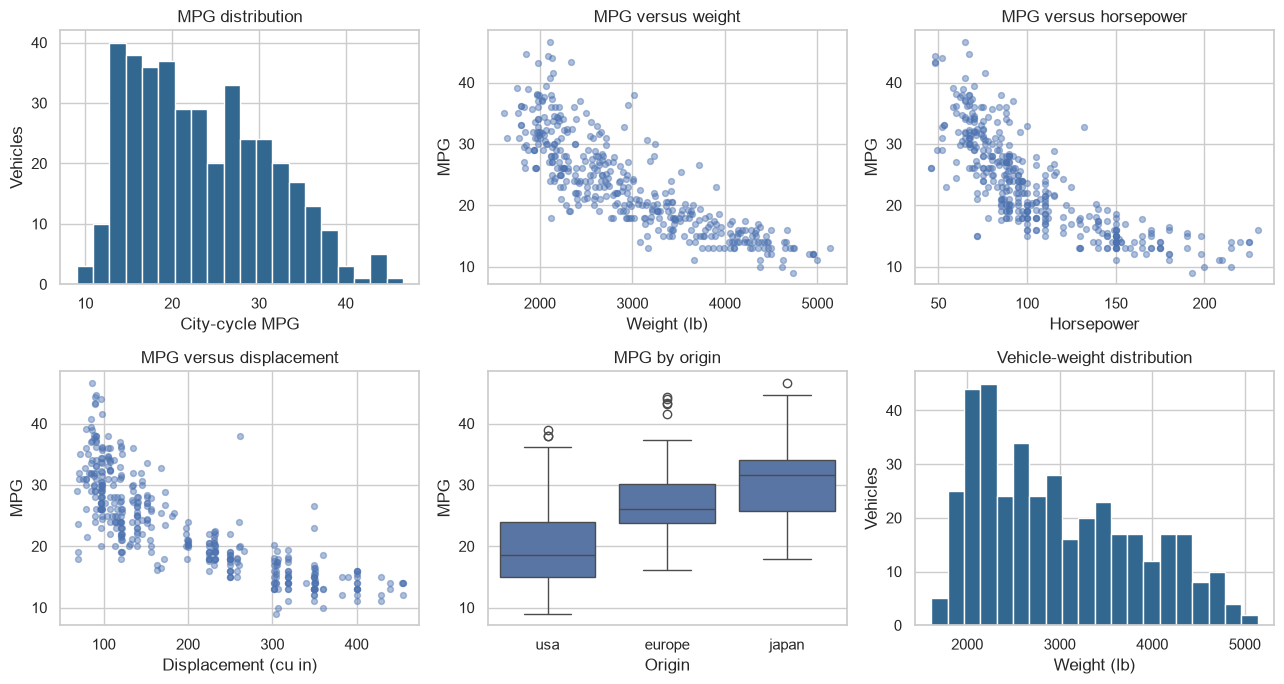


Pearson correlations: MPG associations and predictor redundancy


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
mpg,1.0000,-0.7776,-0.8051,-0.7784,-0.8322,0.4233,0.5805
cylinders,-0.7776,1.0000,0.9508,0.8430,0.8975,-0.5047,-0.3456
displacement,-0.8051,0.9508,1.0000,0.8973,0.9330,-0.5438,-0.3699
horsepower,-0.7784,0.8430,0.8973,1.0000,0.8645,-0.6892,-0.4164
weight,-0.8322,0.8975,0.9330,0.8645,1.0000,-0.4168,-0.3091
acceleration,0.4233,-0.5047,-0.5438,-0.6892,-0.4168,1.0000,0.2903
model_year,0.5805,-0.3456,-0.3699,-0.4164,-0.3091,0.2903,1.0000


Correlations with MPG, excluding MPG itself:


,Correlation with MPG
weight,-0.8322
displacement,-0.8051
horsepower,-0.7784
cylinders,-0.7776
acceleration,0.4233
model_year,0.5805


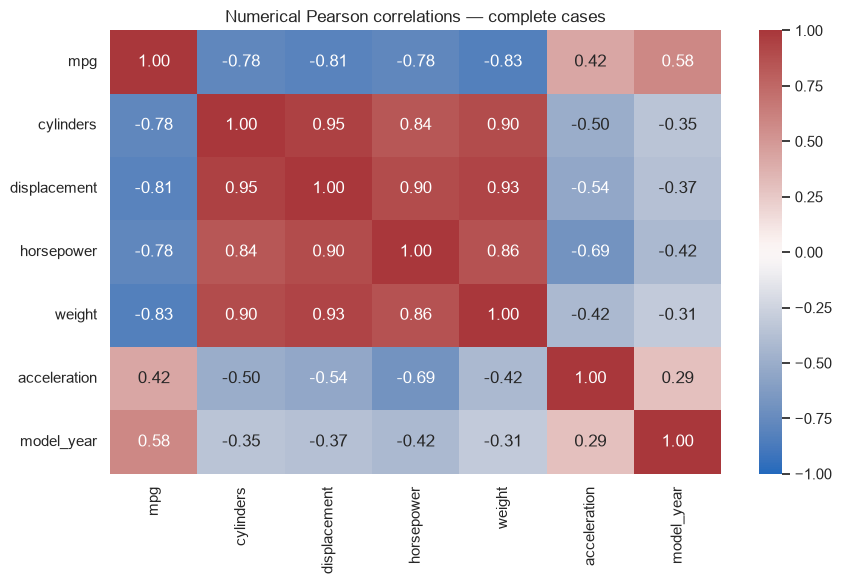

In [2]:
# 1. Use a common complete-case sample so all models compare the same vehicles.
data = raw.dropna().copy()
# The category order makes USA the reference in treatment-coded regression.
data["origin"] = pd.Categorical(data.origin, categories=["usa", "europe", "japan"])
numeric = [
    "mpg",
    "cylinders",
    "displacement",
    "horsepower",
    "weight",
    "acceleration",
    "model_year",
]
assert len(raw) == 398 and len(data) == 392
assert data[numeric].notna().all().all() and np.isfinite(data[numeric]).all().all()
assert (
    data.origin.notna().all()
    and (data[["mpg", "weight", "horsepower", "displacement"]] > 0).all().all()
)
print(
    "Complete-case policy: before / excluded / retained:",
    len(raw),
    len(raw) - len(data),
    len(data),
)
# 2. Screen unusual values using IQR fences; flagging does not remove vehicles.
outlier_rows = []
for col in ["mpg", "weight", "horsepower", "displacement", "acceleration"]:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append(
        [col, low, high, int(((data[col] < low) | (data[col] > high)).sum())]
    )
print("\nIQR assessment: flags are retained unless an error is established")
display(
    pd.DataFrame(
        outlier_rows,
        columns=["Variable", "Lower fence", "Upper fence", "Flagged vehicles"],
    )
)
# 3. Examine target distributions, nonlinear patterns and unadjusted origin differences.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes[0, 0].hist(data.mpg, bins=20, color="#326890")
axes[0, 0].set(title="MPG distribution", xlabel="City-cycle MPG", ylabel="Vehicles")
for ax, col, label in zip(
    [axes[0, 1], axes[0, 2], axes[1, 0]],
    ["weight", "horsepower", "displacement"],
    ["Weight (lb)", "Horsepower", "Displacement (cu in)"],
):
    ax.scatter(data[col], data.mpg, alpha=0.45, s=18)
    ax.set(xlabel=label, ylabel="MPG", title="MPG versus " + col)
sns.boxplot(data=data, x="origin", y="mpg", ax=axes[1, 1])
axes[1, 1].set(title="MPG by origin", xlabel="Origin", ylabel="MPG")
axes[1, 2].hist(data.weight, bins=20, color="#326890")
axes[1, 2].set(
    title="Vehicle-weight distribution", xlabel="Weight (lb)", ylabel="Vehicles"
)
plt.tight_layout()
plt.show()
# 4. Assess linear associations and redundancy before choosing specifications.
correlation = data[numeric].corr()
print("\nPearson correlations: MPG associations and predictor redundancy")
display(correlation)
print("Correlations with MPG, excluding MPG itself:")
display(correlation.mpg.drop("mpg").sort_values().to_frame("Correlation with MPG"))
plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Numerical Pearson correlations — complete cases")
plt.tight_layout()
plt.show()

### What exploration implies for modelling
The scatter plots suggest decreasing MPG with vehicle mass and engine size, with possible
curvature rather than one constant slope. Origin groups also have different MPG distributions,
but these comparisons are not adjusted for weight or year. Correlations summarize linear
associations, not causal effects. Weight, displacement, cylinders and horsepower describe related
engine/vehicle characteristics, so including all of them may inflate coefficient uncertainty.

These full-sample plots are descriptive; subsequent model development and selection use training
data only. I retain the positive extreme observations, revisit influence after fitting and use
the same 392 complete cases throughout. No scaling or encoding is learned from the holdout set.

Numerically, weight has the largest negative correlation with MPG (r = -0.832), while model year has the largest positive correlation (r = 0.581) among the numerical predictors. Displacement and cylinders correlate at 0.951, and displacement and weight at 0.933. These large absolute linear associations explain why conditional engine coefficients may be unstable even when overall fit improves. IQR screening flags ten horsepower and eleven acceleration observations, but none in MPG, weight or displacement; no flagged valid vehicle is deleted.

## Part 2 — Model development and validation (10 marks)
### Common split and focused specifications
The aim is both explanatory and predictive: conditional associations help interpret historical
fuel efficiency, while unseen observations assess prediction. Neither establishes causation.
I reserve 20% of vehicles as a test set (seed 42) and use five-fold cross-validation within the
remaining training set for selection. The test set is evaluated only after the choice is fixed.

**M1** uses weight as an interpretable baseline. **M2** adds all six numerical predictors and
categorical origin, exposing possible redundancy. **M3** keeps weight, a quadratic weight term,
model year and origin: it addresses the observed curvature and avoids the overlapping engine-size
descriptors. This is one planned refinement, not automated p-value elimination. Weight is measured
in thousands of pounds and centred using the training mean; year is centred at 1976. Centring
improves the interpretation of polynomial terms without changing their model space.

In [3]:
# 1. Reserve a common holdout set; model selection will use training data only.
train, test = train_test_split(data, test_size=0.20, random_state=RANDOM_SEED)
train = train.copy()
test = test.copy()
# Centre weight using training data and express it in thousands of pounds.
weight_centre = train.weight.mean() / 1000
for frame in [train, test]:
    frame["w"] = frame.weight / 1000 - weight_centre
    frame["year"] = frame.model_year - 76
assert set(train.index).isdisjoint(test.index)
# 2. Compare a baseline, a full linear model and one interpretable refinement.
formulas = {
    "M1 weight": "mpg ~ weight",
    "M2 full linear": "mpg ~ weight + horsepower + displacement + cylinders + acceleration + model_year + C(origin)",
    "M3 reduced quadratic": "mpg ~ w + I(w ** 2) + year + C(origin)",
}
# Fit each OLS specification to the identical training observations.
models = {
    name: smf.ols(formula, data=train).fit() for name, formula in formulas.items()
}
print(
    "Common training / untouched test counts:",
    len(train),
    len(test),
    "| seed:",
    RANDOM_SEED,
)
print(
    "Origin reference category: usa; centred weight reference (lb):",
    weight_centre * 1000,
)
display(pd.Series(formulas, name="Formula").to_frame())
# 3. Report coefficient estimates and classical uncertainty for each specification.
for name, model in models.items():
    print(
        "\n" + name + " — coefficients, classical SE, t tests and 95% confidence limits"
    )
    ci = model.conf_int()
    display(
        pd.DataFrame(
            {
                "Coefficient": model.params,
                "SE": model.bse,
                "t": model.tvalues,
                "p-value": model.pvalues,
                "95% lower": ci.iloc[:, 0],
                "95% upper": ci.iloc[:, 1],
            }
        )
    )
print(
    "\nTraining fit and overall classical F tests (null: all non-intercept coefficients are zero)"
)
# 4. Compare training fit and joint model significance, accounting for complexity.
fit_table = pd.DataFrame(
    [
        [name, m.rsquared, m.rsquared_adj, m.aic, m.bic, m.fvalue, m.f_pvalue]
        for name, m in models.items()
    ],
    columns=["Model", "Train R2", "Adjusted R2", "AIC", "BIC", "F", "F p-value"],
).set_index("Model")
display(fit_table)
print("\nNested comparison M1 versus M2: classical partial F test")
# M1 is nested in M2; M2 and M3 are not nested and are not compared with this test.
display(anova_lm(models["M1 weight"], models["M2 full linear"]))

Common training / untouched test counts: 313 79 | seed: 42
Origin reference category: usa; centred weight reference (lb): 2986.1246006389774


,Formula
M1 weight,mpg ~ weight
M2 full linear,mpg ~ weight + horsepower + displacement + cyl...
M3 reduced quadratic,mpg ~ w + I(w ** 2) + year + C(origin)



M1 weight — coefficients, classical SE, t tests and 95% confidence limits


,Coefficient,SE,t,p-value,95% lower,95% upper
Intercept,47.2005,0.9141,51.6379,0.0000,45.4020,48.9991
weight,-0.0079,0.0003,-26.8216,0.0000,-0.0085,-0.0073



M2 full linear — coefficients, classical SE, t tests and 95% confidence limits


,Coefficient,SE,t,p-value,95% lower,95% upper
Intercept,-19.3319,5.4460,-3.5498,0.0004,-30.0485,-8.6154
C(origin)[T.europe],2.8755,0.6560,4.3835,0.0000,1.5847,4.1663
C(origin)[T.japan],3.2060,0.6198,5.1726,0.0000,1.9863,4.4256
weight,-0.0064,0.0007,-8.8328,0.0000,-0.0079,-0.0050
horsepower,-0.0216,0.0155,-1.3907,0.1653,-0.0522,0.0090
displacement,0.0192,0.0086,2.2219,0.0270,0.0022,0.0362
cylinders,-0.3421,0.3704,-0.9236,0.3564,-1.0710,0.3868
acceleration,0.0422,0.1098,0.3844,0.7010,-0.1738,0.2582
model_year,0.7972,0.0604,13.1964,0.0000,0.6783,0.9160


... (2 outputs left out)


Training fit and overall classical F tests (null: all non-intercept coefficients are zero)


,Train R2,Adjusted R2,AIC,BIC,F,F p-value
Model,,,,,,
M1 weight,0.6982,0.6972,1814.6071,1822.0995,719.3970,0.0000
M2 full linear,0.8287,0.8242,1651.3383,1685.0542,183.8156,0.0000
M3 reduced quadratic,0.8594,0.8571,1583.5589,1606.0361,375.2136,0.0000



Nested comparison M1 versus M2: classical partial F test


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,311.0000,5961.1182,0.0000,NaN,NaN,NaN
1,304.0000,3383.4782,7.0000,2577.6401,33.0853,0.0000


The baseline slope is an average expected MPG difference per additional pound; its intercept
describes a zero-weight car and has no realistic physical interpretation. Multiple-model
coefficients are conditional on included predictors. A small p-value is evidence against a
specified null under the inferential assumptions, not the probability that the null is true,
and significance does not establish a large or practically important effect. M2 and M3 are
not nested, so I compare their AIC/BIC and training cross-validation rather than applying an
invalid partial F test between them.

The baseline weight slope is -0.007904 MPG per lb (about -0.790 MPG per 100 lb), with a classical 95% interval approximately [-0.848, -0.732] per 100 lb. Its unrealistic zero-weight intercept is not a practical prediction. All three overall classical F tests provide evidence against their joint slope-null hypotheses; displayed p-values rounded to 0.0000 are small, not exactly zero. The nested M1-to-M2 partial F is 33.09 for seven added terms. Its classical reference distribution is qualified by the later heteroscedasticity findings. In M2, the positive conditional displacement coefficient despite negative marginal correlation illustrates why correlated predictors should not be interpreted as independent physical mechanisms.

In [4]:
print(
    "VIF on each training design matrix; intercept included in calculation but not reported"
)
# 1. Calculate VIF on the fitted design, including its intercept and valid dummy coding.
vif_tables = {}
for name, m in models.items():
    X = m.model.exog
    table = pd.DataFrame(
        {
            "Term": m.model.exog_names,
            "VIF": [variance_inflation_factor(X, i) for i in range(X.shape[1])],
        }
    )
    vif_tables[name] = table[table.Term != "Intercept"]
    print("\n" + name)
    display(vif_tables[name])
# 2. Reuse the same five training folds for a fair predictive comparison.
folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(train))
cv_rows = []
for name, formula in formulas.items():
    errors = []
    # Fit on the fold training subset and predict only its validation subset.
    for fitting, validation in folds:
        fitted = smf.ols(formula, data=train.iloc[fitting]).fit()
        errors.append(
            np.sqrt(
                mean_squared_error(
                    train.iloc[validation].mpg, fitted.predict(train.iloc[validation])
                )
            )
        )
    cv_rows.append([name, np.mean(errors), np.std(errors, ddof=1)])
cv = pd.DataFrame(cv_rows, columns=["Model", "CV RMSE", "Fold RMSE SD"]).set_index(
    "Model"
)
# Freeze the selected specification before evaluating any holdout outcomes.
selected = cv["CV RMSE"].idxmin()
final = models[selected]
print(
    "\nTraining-only model comparison: RMSE in MPG; fold SD is not a confidence interval"
)
display(fit_table.join(cv))
print("Selected before viewing test performance:", selected)

VIF on each training design matrix; intercept included in calculation but not reported

M1 weight


,Term,VIF
1,weight,1.0000



M2 full linear


,Term,VIF
1,C(origin)[T.europe],1.5712
2,C(origin)[T.japan],1.7368
3,weight,10.4865
4,horsepower,9.9305
5,displacement,22.5538
6,cylinders,11.1211
7,acceleration,2.6830
8,model_year,1.3480



M3 reduced quadratic


,Term,VIF
1,C(origin)[T.europe],1.3014
2,C(origin)[T.japan],1.6426
3,w,2.1194
4,I(w ** 2),1.3722
5,year,1.1770



Training-only model comparison: RMSE in MPG; fold SD is not a confidence interval


,Train R2,Adjusted R2,AIC,BIC,F,F p-value,CV RMSE,Fold RMSE SD
Model,,,,,,,,
M1 weight,0.6982,0.6972,1814.6071,1822.0995,719.3970,0.0000,4.3646,0.6003
M2 full linear,0.8287,0.8242,1651.3383,1685.0542,183.8156,0.0000,3.3671,0.4672
M3 reduced quadratic,0.8594,0.8571,1583.5589,1606.0361,375.2136,0.0000,3.0334,0.3967


Selected before viewing test performance: M3 reduced quadratic


VIF values above about 5–10 warrant attention, but are not automatic deletion rules. VIF
quantifies variance inflation relative to orthogonal predictors and affects coefficient precision,
not necessarily prediction. I include an intercept and treatment-coded origin without a redundant
dummy set. Indicator VIFs are column diagnostics, not a generalized multi-degree-of-freedom test
of origin. The polynomial can have structural collinearity; training centring reduces this.
The fold-mean RMSE guides selection, considered alongside complexity and diagnostics.

The full model has VIFs of 22.55 for displacement, 11.12 for cylinders, 10.49 for weight and 9.93 for horsepower. The selected reduced model has no reported predictor VIF above 2.12. CV RMSE declines from 4.365 (M1) to 3.367 (M2) to 3.033 (M3), while AIC declines from 1814.61 to 1651.34 to 1583.56. This combination supports M3 over both a simple baseline and a more redundant linear specification. The 0.334-MPG CV improvement over M2 is useful but modest, and the five fold scores are not independent evidence for a formal significance claim. The training mean used for weight centring merely translates the polynomial basis; it uses no test information and does not change the function space within a fold.

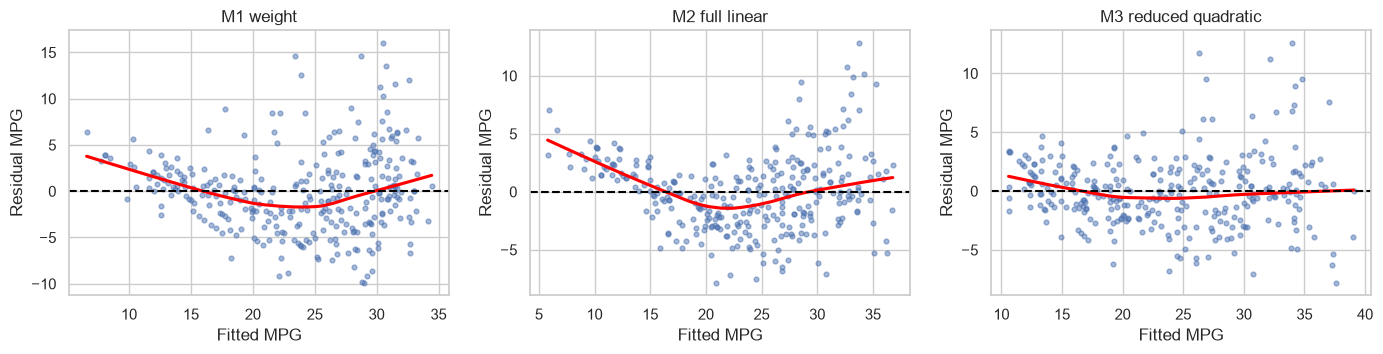

Training diagnostics: BP tests constant variance; JB tests normality; RESET checks specification


,BP p-value,Jarque-Bera p-value,RESET p-value,DW (unordered rows)
Model,,,,
M1 weight,0.0001,0.0000,0.0000,2.2031
M2 full linear,0.0005,0.0000,0.0000,1.9883
M3 reduced quadratic,0.0000,0.0000,0.0005,1.9369


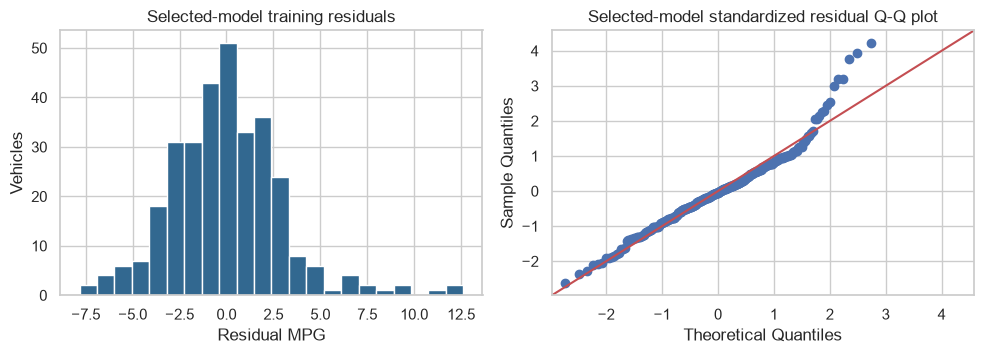

Selected-model HC3 coefficient inference: robust to heteroscedasticity, not misspecification


,Coefficient,HC3 SE,HC3 p-value,HC3 95% lower,HC3 95% upper
Intercept,21.2675,0.2354,0.0000,20.8042,21.7308
C(origin)[T.europe],1.8553,0.7146,0.0099,0.4493,3.2613
C(origin)[T.japan],1.2970,0.5835,0.0269,0.1489,2.4452
w,-7.0627,0.2878,0.0000,-7.6290,-6.4963
I(w ** 2),2.2766,0.2479,0.0000,1.7887,2.7644
year,0.8703,0.0552,0.0000,0.7616,0.9789


Most influential training observations (screening threshold Cook D > 4/n):


,Vehicle,CooksD,Leverage,Studentized residual
326,vw dasher (diesel),0.0623,0.0255,3.8679
327,audi 5000s (diesel),0.0576,0.0322,3.2739
322,mazda glc,0.0535,0.0176,4.3549
325,vw rabbit c (diesel),0.0499,0.0284,3.2480
332,vokswagen rabbit,0.0464,0.0380,-2.6800
244,volkswagen rabbit custom diesel,0.0430,0.0280,3.0357
387,oldsmobile cutlass ciera (diesel),0.0405,0.0155,4.0205
275,volvo 264gl,0.0286,0.0312,-2.3237


Cook flags: 26 | leverage flags: 12
Coefficient sensitivity after omitting screened Cook flags (not a replacement final fit):


,All training vehicles,Cook-screen subset
Intercept,21.2675,21.2236
C(origin)[T.europe],1.8553,0.9240
C(origin)[T.japan],1.2970,0.9752
w,-7.0627,-7.2557
I(w ** 2),2.2766,2.3318
year,0.8703,0.7746


Scientific-notation view of diagnostic p-values (avoids interpreting rounded zeros as p=0):
                      BP p-value  Jarque-Bera p-value  RESET p-value
Model                                                               
M1 weight               0.000119              7.6e-09       6.62e-07
M2 full linear          0.000457             6.75e-07       4.17e-20
M3 reduced quadratic    9.07e-07             2.51e-22       0.000499


In [5]:
# 1. Examine residual patterns and formal tests for all three fitted models.
diagnostics = []
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, (name, m) in zip(axes, models.items()):
    sns.regplot(
        x=m.fittedvalues,
        y=m.resid,
        lowess=True,
        scatter_kws={"s": 12, "alpha": 0.5},
        line_kws={"color": "red"},
        ax=ax,
    )
    ax.axhline(0, color="black", ls="--")
    ax.set(title=name, xlabel="Fitted MPG", ylabel="Residual MPG")
    # BP: constant variance; JB: residual normality; RESET: mean specification.
    bp = het_breuschpagan(m.resid, m.model.exog)
    jb = stats.jarque_bera(m.resid)
    reset = linear_reset(m, power=2, use_f=True)
    diagnostics.append(
        [name, bp[1], jb.pvalue, float(reset.pvalue), durbin_watson(m.resid)]
    )
plt.tight_layout()
plt.show()
diagnostic_table = pd.DataFrame(
    diagnostics,
    columns=[
        "Model",
        "BP p-value",
        "Jarque-Bera p-value",
        "RESET p-value",
        "DW (unordered rows)",
    ],
).set_index("Model")
print(
    "Training diagnostics: BP tests constant variance; JB tests normality; RESET checks specification"
)
display(diagnostic_table)
# 2. Inspect the selected model more closely using a histogram and Q-Q plot.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
axes[0].hist(final.resid, bins=22, color="#326890")
axes[0].set(
    title="Selected-model training residuals", xlabel="Residual MPG", ylabel="Vehicles"
)
sm.qqplot(final.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Selected-model standardized residual Q-Q plot")
plt.tight_layout()
plt.show()
# 3. HC3 adjusts coefficient inference; it does not repair the mean or individual PIs.
robust = final.get_robustcov_results(cov_type="HC3")
rci = robust.conf_int()
robust_table = pd.DataFrame(
    {
        "Coefficient": final.params,
        "HC3 SE": robust.bse,
        "HC3 p-value": robust.pvalues,
        "HC3 95% lower": rci[:, 0],
        "HC3 95% upper": rci[:, 1],
    }
)
print(
    "Selected-model HC3 coefficient inference: robust to heteroscedasticity, not misspecification"
)
display(robust_table)
# 4. Identify influential training vehicles without automatically deleting them.
influence = final.get_influence()
influence_table = pd.DataFrame(
    {
        "Vehicle": train.name,
        "CooksD": influence.cooks_distance[0],
        "Leverage": influence.hat_matrix_diag,
        "Studentized residual": influence.resid_studentized_external,
    }
)
print("Most influential training observations (screening threshold Cook D > 4/n):")
display(influence_table.sort_values("CooksD", ascending=False).head(8))
# Leverage screening uses 2p/n, counting the intercept among the p parameters.
print(
    "Cook flags:",
    (influence_table.CooksD > 4 / len(train)).sum(),
    "| leverage flags:",
    (influence_table.Leverage > 2 * len(final.params) / len(train)).sum(),
)
# Sensitivity check only; flagged observations are not removed from the final model.
keep = influence_table.CooksD.le(4 / len(train))
sensitivity = smf.ols(formulas[selected], data=train.loc[keep]).fit()
print(
    "Coefficient sensitivity after omitting screened Cook flags (not a replacement final fit):"
)
display(
    pd.DataFrame(
        {
            "All training vehicles": final.params,
            "Cook-screen subset": sensitivity.params,
        }
    )
)
# Scientific notation makes very small p-values visible instead of rounded zeros.
print(
    "Scientific-notation view of diagnostic p-values (avoids interpreting rounded zeros as p=0):"
)
print(
    diagnostic_table[["BP p-value", "Jarque-Bera p-value", "RESET p-value"]].to_string(
        float_format=lambda value: f"{value:.3g}"
    )
)

Residual curvature suggests a mean-specification problem; a fan-shaped spread suggests unequal
variance. Formal tests complement rather than replace the plots, and failure to reject is not
proof of an assumption. Residual normality matters for classical finite-sample inference and
intervals, not as an absolute prerequisite for useful point predictions. HC3 changes coefficient
standard errors, confidence limits and tests; it does not change the fitted mean function or
automatically repair individual prediction intervals.

There is no justified time sequence or experimental sampling design here. Durbin–Watson is
shown descriptively on the random training-row ordering and cannot establish independence.
Shared manufacturers and unrecorded design factors could induce dependence. Cook's distance
and leverage are screening tools, not proof of erroneous vehicles. I retain flagged observations
and compare coefficient sensitivity instead of deleting cases to improve scores.

For M3, Breusch-Pagan and Jarque-Bera reject their nulls at 0.001; RESET also rejects at approximately p = 0.0005. Thus the quadratic refinement improves prediction but does not remove all model inadequacy. Its residual spread and upper-tail observations should remain visible. HC3 inference addresses variance misspecification for coefficient tests, while neither HC3 nor a high R-squared corrects an inadequate conditional mean or dependence.

Twenty-six training observations exceed the Cook threshold 4/313. The sensitivity fit changes the Europe-versus-USA coefficient from 1.855 to 0.924 MPG and the year coefficient from 0.870 to 0.775, while the centred linear weight coefficient changes from -7.063 to -7.256. This particularly qualifies the precision and stability of the origin comparison. Several influential car names identify diesels, suggesting that a properly recorded fuel-type variable could help future analysis; that is a hypothesis, not a demonstrated explanation. The screening subset is not substituted for the selected final model.

Single holdout evaluation for the common test vehicles; selection is not revised using this table


,Test RMSE,Test MAE,Test R2
Model,,,
M1 weight,4.2064,3.4641,0.6533
M2 full linear,3.2561,2.4620,0.7923
M3 reduced quadratic,3.0479,2.2614,0.8180


Five real held-out vehicles: 95% mean-response confidence intervals and individual prediction intervals


,Vehicle,Actual MPG,Predicted MPG,Mean CI lower,Mean CI upper,Individual PI lower,Individual PI upper
79,renault 12 (sw),26.0000,26.7180,25.7523,27.6838,20.7212,32.7149
276,saab 99gle,21.6000,26.2964,25.3410,27.2518,20.3012,32.2916
248,honda civic cvcc,36.1000,35.8852,34.9815,36.7889,29.8981,41.8724
56,plymouth cricket,26.0000,26.6190,25.4609,27.7772,20.5882,32.6499
393,ford mustang gl,27.0000,27.9620,27.2334,28.6906,21.9987,33.9252


Selected-model empirical holdout individual-interval coverage: 0.9493670886075949


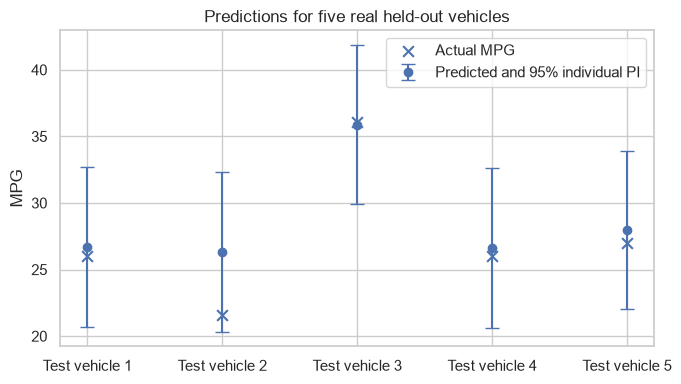

In [6]:
# Test outcomes are used once after training-only model selection is frozen.
# 1. Compare all candidates on the same untouched holdout observations.
performance = []
for name, m in models.items():
    pred = m.predict(test)
    rmse = np.sqrt(mean_squared_error(test.mpg, pred))
    mae = mean_absolute_error(test.mpg, pred)
    r2 = r2_score(test.mpg, pred)
    # Check the metric-library results against their direct mathematical definitions.
    assert np.isclose(rmse, np.sqrt(np.mean((test.mpg - pred) ** 2)))
    assert np.isclose(mae, np.mean(np.abs(test.mpg - pred)))
    assert np.isclose(
        r2,
        1 - np.sum((test.mpg - pred) ** 2) / np.sum((test.mpg - test.mpg.mean()) ** 2),
    )
    performance.append([name, rmse, mae, r2])
test_results = pd.DataFrame(
    performance, columns=["Model", "Test RMSE", "Test MAE", "Test R2"]
).set_index("Model")
print(
    "Single holdout evaluation for the common test vehicles; selection is not revised using this table"
)
display(test_results)
# 2. Use five real held-out vehicles for predictions and uncertainty intervals.
examples = test.iloc[:5].copy()
# Classical OLS intervals: mean-response CI versus wider individual-vehicle PI.
intervals = final.get_prediction(examples).summary_frame(alpha=0.05)
predictions = pd.DataFrame(
    {
        "Vehicle": examples.name,
        "Actual MPG": examples.mpg,
        "Predicted MPG": intervals["mean"],
        "Mean CI lower": intervals.mean_ci_lower,
        "Mean CI upper": intervals.mean_ci_upper,
        "Individual PI lower": intervals.obs_ci_lower,
        "Individual PI upper": intervals.obs_ci_upper,
    }
)
print(
    "Five real held-out vehicles: 95% mean-response confidence intervals and individual prediction intervals"
)
display(predictions)
# 3. Check empirical coverage on this holdout, without using it to redesign the model.
all_intervals = final.get_prediction(test).summary_frame(alpha=0.05)
coverage = (
    (test.mpg >= all_intervals.obs_ci_lower) & (test.mpg <= all_intervals.obs_ci_upper)
).mean()
print("Selected-model empirical holdout individual-interval coverage:", coverage)
assert (intervals.obs_ci_lower <= intervals.mean_ci_lower).all() and (
    intervals.obs_ci_upper >= intervals.mean_ci_upper
).all()
assert np.allclose(intervals["mean"], final.predict(examples))
assert np.isfinite(final.params).all() and final.nobs == len(train)
# 4. Display actual outcomes alongside predicted MPG and individual prediction intervals.
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(5)
ax.errorbar(
    x,
    predictions["Predicted MPG"],
    yerr=[
        predictions["Predicted MPG"] - predictions["Individual PI lower"],
        predictions["Individual PI upper"] - predictions["Predicted MPG"],
    ],
    fmt="o",
    capsize=5,
    label="Predicted and 95% individual PI",
)
ax.scatter(x, predictions["Actual MPG"], marker="x", s=60, label="Actual MPG")
ax.set(
    xticks=x,
    xticklabels=["Test vehicle " + str(i + 1) for i in x],
    ylabel="MPG",
    title="Predictions for five real held-out vehicles",
)
ax.legend()
plt.tight_layout()
plt.show()

A mean-response confidence interval describes uncertainty about expected MPG at the stated
predictor values. An individual prediction interval also includes residual vehicle-to-vehicle
variation and is wider. The displayed intervals use the selected classical OLS fit and its
constant residual-variance estimate. They do not gain heteroscedasticity validity merely because
HC3 inference was reported separately. Neither model-selection uncertainty nor population bias
is covered. Holdout coverage is an empirical check on this one small split, not a guarantee of
95% coverage on future vehicles.

For the held-out Renault 12 (sw), predicted MPG is 26.72, compared with the recorded 26.00. The 95% confidence interval for its expected mean is [25.75, 27.68], whereas the individual interval is [20.72, 32.71]. The latter is wider because it includes residual vehicle variation. Across all 79 test vehicles, 75 fall inside the nominal individual intervals (94.94%). This observed proportion is compatible with roughly nominal coverage on this split but cannot establish valid conditional coverage under the detected heteroscedasticity or for new populations. The model remains fitted to training data only; no full-data refit or test-driven redesign is used for the reported inference and predictions.

In [7]:
# Independent interval arithmetic and VIF check; no refitting of the selected model.
assert final.model.exog_names == [
    "Intercept",
    "C(origin)[T.europe]",
    "C(origin)[T.japan]",
    "w",
    "I(w ** 2)",
    "year",
]
# Construct the selected formula explicitly, independently of its formula parser.
Xp = np.column_stack(
    [
        np.ones(len(examples)),
        examples.origin.eq("europe").astype(float),
        examples.origin.eq("japan").astype(float),
        examples.w,
        examples.w**2,
        examples.year,
    ]
)
# Reconstruct the predicted means and their covariance-based uncertainty.
manual_mean = Xp @ np.asarray(final.params)
manual_mean_var = np.einsum("ij,jk,ik->i", Xp, np.asarray(final.cov_params()), Xp)
# Use the two-sided 95% Student-t critical value with residual degrees of freedom.
tcrit = stats.t.ppf(0.975, final.df_resid)
assert np.allclose(intervals["mean"], manual_mean)
assert np.allclose(
    intervals.mean_ci_lower, manual_mean - tcrit * np.sqrt(manual_mean_var)
)
assert np.allclose(
    intervals.obs_ci_lower,
    manual_mean - tcrit * np.sqrt(manual_mean_var + final.mse_resid),
)
assert np.allclose(
    intervals.obs_ci_upper,
    manual_mean + tcrit * np.sqrt(manual_mean_var + final.mse_resid),
)
# Check VIF independently through auxiliary regressions on the other design columns.
X = final.model.exog
for j in range(1, X.shape[1]):
    others = np.delete(X, j, axis=1)
    aux = sm.OLS(X[:, j], others).fit()
    assert np.isclose(variance_inflation_factor(X, j), 1 / (1 - aux.rsquared))
# Confirm that splitting retained the entire common sample and preserved the original data.
assert len(train) + len(test) == len(data) and raw.shape == (398, 9)
print(
    "Checks passed: independent 95% interval arithmetic, VIF auxiliary regressions, metrics and common sample."
)

Checks passed: independent 95% interval arithmetic, VIF auxiliary regressions, metrics and common sample.


## Part 3 - Interpretation and insights (4 marks)
### Relationships, effect sizes and practical meaning
The evidence supports a curved conditional association between vehicle weight and historical MPG, rather than one universal linear penalty. In M3, w is weight in thousands of pounds centred at 2,986.12 lb. The fitted weight derivative is **-7.063 + 2 * 2.277 * w MPG per 1,000 lb**. At 3,000 lb this is approximately -7.00 MPG per 1,000 lb (a local -0.70 per 100 lb); at 4,000 lb it is about -2.45 per 1,000 lb. These are local slopes, not a guaranteed effect of adding mass. The positive quadratic term flattens the fitted relationship and can eventually reverse its sign in the heavy tail, so extrapolating it as a physical law would be inappropriate.

Holding model weight and origin fixed, one later model year is associated with 0.870 additional MPG (HC3 95% CI [0.762, 0.979]). This historical pattern can reflect technology, regulation or vehicle mix, but the data do not isolate those causes. Relative to USA, Europe is associated with 1.855 additional MPG (HC3 CI [0.449, 3.261], p = 0.0099), and Japan with 1.297 (HC3 CI [0.149, 2.445], p = 0.0269). These origin differences are conditional comparisons, not inherent country effects; the Cook sensitivity analysis especially weakens a firm interpretation of the Europe magnitude.

### Model choice and its limits
I prefer M3 because training-only CV, adjusted R-squared, AIC/BIC and lower predictor VIF collectively favour a compact curved specification. The untouched-test RMSE improvement over M2 is about 0.208 MPG, and its improvement over the baseline is 1.159 MPG. The test evidence supports the earlier choice without being used to revise it. An R-squared of 0.818 describes explained variation relative to the test-set mean, not "81.8% accurate predictions." Typical absolute error is represented more directly by the 2.261-MPG MAE, and individual uncertainty is substantially wider than uncertainty in a fitted mean.

The sample describes 1970-1982 vehicles. It is observational, with six missing-horsepower exclusions whose selection mechanism is unknown. Important design and fuel-type attributes are absent. Correlated engine descriptors limit their separate interpretation, and the remaining BP, JB and RESET rejections warn that a simple quadratic mean with constant residual variance is incomplete. Random splitting estimates performance for similarly sampled historical vehicles; it is not a temporal or manufacturer-held-out generalization test. Treating model year as a linear trend and cylinders as a numerical descriptor in M2 are explicit modelling assumptions. The origin sample composition and influential vehicles constrain subgroup conclusions.

### Recommendations and further analysis
For historical efficiency comparisons, use weight together with year and origin context rather than ranking vehicles from engine size alone, and communicate prediction intervals alongside point estimates. Do not promise a specific MPG improvement from changing one feature: this design does not identify intervention effects. Collect reliable fuel type, transmission, engine technology and manufacturer identifiers to investigate omitted structure and potential clustering, rather than extracting unverified categories from car names.

Before applying the model to current vehicles, seek a genuinely external, newer sample and evaluate error, interval coverage and calibration by relevant subgroups and weight ranges. Manufacturer-grouped or chronological validation would answer different generalization questions from this random split. Further modelling could examine justified interactions or a variance model, but these should be planned using development data and validated externally rather than selected by repeatedly checking this holdout.

The investigation establishes useful historical conditional patterns and a predictive improvement over weight alone. It does not establish causation, eliminate model-selection uncertainty or guarantee calibrated individual forecasts outside the sampled population.

### Sources and reproducibility
Quinlan, R. (1993). *Auto MPG* [Dataset]. UCI Machine Learning Repository.
https://doi.org/10.24432/C5859H. Seaborn's dataset distribution:
https://github.com/mwaskom/seaborn-data/blob/master/mpg.csv.
Statsmodels OLS results/prediction documentation:
https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.html.
The original CSV is embedded without alteration. Model formulas, seed, split, and validation
calculations appear above; no external script or CSV is a submission dependency.